In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import copy
import time
import json

SEED = 42
EPOCHS = 10
BATCH_SIZE = 128
LR = 0.001
WEIGHT_DECAY = 0.0001
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hardware = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print("Device:", device, hardware)

def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()



MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2023, 0.1994, 0.2010)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
full_train = datasets.CIFAR10("data", train=True, download=True, transform=transform)
indices = np.random.RandomState(SEED).permutation(len(full_train)).tolist()
train_indices, val_indices = indices[:45000], indices[45000:]
train_data = Subset(full_train, train_indices)
val_data = Subset(full_train, val_indices)
train_eval_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
classes = full_train.classes
assert len(train_data) == 45000 and len(val_data) == 5000
assert not set(train_indices).intersection(val_indices)

def make_train_loader(seed):
    return DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

print("Train:", len(train_data), "Validation:", len(val_data))


Device: cuda Tesla T4


100%|██████████| 170M/170M [26:08<00:00, 109kB/s]


Train: 45000 Validation: 5000


In [2]:
class AlexNetLike(nn.Module):
    def __init__(self):
        super(AlexNetLike, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
            nn.Linear(128 * 2 * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.head(self.features(x))

class VGGLike(nn.Module):
    def __init__(self):
        super(VGGLike, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
            nn.Linear(128 * 2 * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.head(self.features(x))

class VGGGap(nn.Module):
    def __init__(self):
        super(VGGGap, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.head(self.features(x))


In [3]:
class InceptionModulePlain(nn.Module):
    def __init__(self, in_channels):
        super(InceptionModulePlain, self).__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.ReLU()
        )
        self.b2 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU()
        )
        self.b3 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=5, padding=2),
            nn.ReLU()
        )
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.ReLU()
        )

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class InceptionModuleBottleneck(nn.Module):
    def __init__(self, in_channels):
        super(InceptionModuleBottleneck, self).__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.ReLU()
        )
        self.b2 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU()
        )
        self.b3 = nn.Sequential(
            nn.Conv2d(in_channels, 8, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(8, 32, kernel_size=5, padding=2),
            nn.ReLU()
        )
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.ReLU()
        )

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class InceptionNet(nn.Module):
    def __init__(self, bottleneck=False):
        super(InceptionNet, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        if bottleneck:
            self.inception = InceptionModuleBottleneck(64)
        else:
            self.inception = InceptionModulePlain(64)

        self.fe = nn.Sequential(
            nn.MaxPool2d(2),
            nn.Conv2d(96, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
            nn.Linear(128 * 2 * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.inception(x)
        x = self.fe(x)
        return self.head(x)


In [4]:
MODEL_NAMES = ["AlexNet-mini", "VGG-mini", "VGG-GAP", "Inception-plain", "Inception-bottleneck"]

def make_model(name):
    if name == "AlexNet-mini":
        return AlexNetLike()
    if name == "VGG-mini":
        return VGGLike()
    if name == "VGG-GAP":
        return VGGGap()
    if name == "Inception-plain":
        return InceptionNet(bottleneck=False)
    if name == "Inception-bottleneck":
        return InceptionNet(bottleneck=True)
    raise ValueError(name)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

parameter_rows = []
shape_rows = []
block_rows = []
expected_counts = {"AlexNet-mini": 194506, "VGG-mini": 353962, "VGG-GAP": 288298,
                   "Inception-plain": 268842, "Inception-bottleneck": 211778}
for name in MODEL_NAMES:
    set_seed(SEED)
    model = make_model(name).to(device)
    model.eval()
    print("\n", name, "\n", model)
    parameter_rows.append({"model": name, "parameters": count_parameters(model),
                           "head_parameters": count_parameters(model.head),
                           "eligible_under_300000": count_parameters(model) <= 300000})
    assert count_parameters(model) == expected_counts[name]
    with torch.no_grad():
        x = torch.zeros(2, 3, 32, 32).to(device)
        for group_name, group in model.named_children():
            layers = list(group.named_children()) if isinstance(group, nn.Sequential) else [("module", group)]
            for layer_name, layer in layers:
                x = layer(x)
                shape_rows.append({"model": name, "layer": group_name + "." + layer_name,
                                   "shape": str(list(x.shape)), "parameters": count_parameters(layer)})
        assert list(x.shape) == [2, 10]
        assert list(model(torch.zeros(2, 3, 32, 32).to(device)).shape) == [2, 10]
    if hasattr(model, "features"):
        block, params = 1, 0
        for layer in model.features:
            params += count_parameters(layer)
            if isinstance(layer, nn.MaxPool2d):
                block_rows.append({"model": name, "block": "features_" + str(block), "parameters": params})
                block += 1
                params = 0
        block_rows.append({"model": name, "block": "head", "parameters": count_parameters(model.head)})
    else:
        for group_name, group in model.named_children():
            block_rows.append({"model": name, "block": group_name, "parameters": count_parameters(group)})
    del model
for row in parameter_rows:
    print(row)
for row in shape_rows:
    print(row)
for row in block_rows:
    print(row)



 AlexNet-mini 
 AlexNetLike(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(2, 2))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

 VGG-mini 
 VGGLike(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)

In [5]:
rf_rows = []
for name, model in [("AlexNet-mini", AlexNetLike()), ("VGG-mini", VGGLike())]:
    rf, jump = 1, 1
    for index, layer in enumerate(model.features):
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):
            kernel = layer.kernel_size[0] if isinstance(layer.kernel_size, tuple) else layer.kernel_size
            stride = layer.stride[0] if isinstance(layer.stride, tuple) else layer.stride
            rf += (kernel - 1) * jump
            jump *= stride
            rf_rows.append({"model": name, "layer": str(index), "operation": type(layer).__name__,
                            "kernel": kernel, "stride": stride, "RF": rf, "jump": jump})
    expected_rf = 28 if name == "AlexNet-mini" else 36
    assert rf == expected_rf and jump == 8
for row in rf_rows:
    print(row)


{'model': 'AlexNet-mini', 'layer': '0', 'operation': 'Conv2d', 'kernel': 5, 'stride': 1, 'RF': 5, 'jump': 1}
{'model': 'AlexNet-mini', 'layer': '2', 'operation': 'MaxPool2d', 'kernel': 2, 'stride': 2, 'RF': 6, 'jump': 2}
{'model': 'AlexNet-mini', 'layer': '3', 'operation': 'Conv2d', 'kernel': 5, 'stride': 1, 'RF': 14, 'jump': 2}
{'model': 'AlexNet-mini', 'layer': '5', 'operation': 'MaxPool2d', 'kernel': 2, 'stride': 2, 'RF': 16, 'jump': 4}
{'model': 'AlexNet-mini', 'layer': '6', 'operation': 'Conv2d', 'kernel': 3, 'stride': 1, 'RF': 24, 'jump': 4}
{'model': 'AlexNet-mini', 'layer': '8', 'operation': 'MaxPool2d', 'kernel': 2, 'stride': 2, 'RF': 28, 'jump': 8}
{'model': 'VGG-mini', 'layer': '0', 'operation': 'Conv2d', 'kernel': 3, 'stride': 1, 'RF': 3, 'jump': 1}
{'model': 'VGG-mini', 'layer': '2', 'operation': 'Conv2d', 'kernel': 3, 'stride': 1, 'RF': 5, 'jump': 1}
{'model': 'VGG-mini', 'layer': '4', 'operation': 'MaxPool2d', 'kernel': 2, 'stride': 2, 'RF': 6, 'jump': 2}
{'model': 'VGG-

In [6]:
branch_rows = []
for name, module in [("plain", InceptionModulePlain(64)), ("bottleneck", InceptionModuleBottleneck(64))]:
    module = module.to(device)
    module.eval()
    with torch.no_grad():
        x = torch.zeros(2, 64, 16, 16).to(device)
        for branch_name in ["b1", "b2", "b3", "b4"]:
            branch = getattr(module, branch_name)
            y = branch(x)
            branch_rows.append({"module": name, "branch": branch_name,
                                "parameters": count_parameters(branch), "shape": str(list(y.shape))})
        output = module(x)
        assert list(output.shape) == [2, 96, 16, 16]
        branch_rows.append({"module": name, "branch": "total",
                            "parameters": count_parameters(module), "shape": str(list(output.shape))})
for row in branch_rows:
    print(row)
plain_module = count_parameters(InceptionModulePlain(64))
compact_module = count_parameters(InceptionModuleBottleneck(64))
plain_net = count_parameters(InceptionNet(False))
compact_net = count_parameters(InceptionNet(True))
reductions = {"module_reduction_percent": 100 * (1 - compact_module / plain_module),
              "network_reduction_percent": 100 * (1 - compact_net / plain_net)}
print(reductions)


{'module': 'plain', 'branch': 'b1', 'parameters': 1040, 'shape': '[2, 16, 16, 16]'}
{'module': 'plain', 'branch': 'b2', 'parameters': 18464, 'shape': '[2, 32, 16, 16]'}
{'module': 'plain', 'branch': 'b3', 'parameters': 51232, 'shape': '[2, 32, 16, 16]'}
{'module': 'plain', 'branch': 'b4', 'parameters': 1040, 'shape': '[2, 16, 16, 16]'}
{'module': 'plain', 'branch': 'total', 'parameters': 71776, 'shape': '[2, 96, 16, 16]'}
{'module': 'bottleneck', 'branch': 'b1', 'parameters': 1040, 'shape': '[2, 16, 16, 16]'}
{'module': 'bottleneck', 'branch': 'b2', 'parameters': 5680, 'shape': '[2, 32, 16, 16]'}
{'module': 'bottleneck', 'branch': 'b3', 'parameters': 6952, 'shape': '[2, 32, 16, 16]'}
{'module': 'bottleneck', 'branch': 'b4', 'parameters': 1040, 'shape': '[2, 16, 16, 16]'}
{'module': 'bottleneck', 'branch': 'total', 'parameters': 14712, 'shape': '[2, 96, 16, 16]'}
{'module_reduction_percent': 79.50289790459206, 'network_reduction_percent': 21.225850127584234}


In [7]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            output = model(x)
            total_loss += criterion(output, y).item() * y.size(0)
            correct += (output.argmax(1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total

fixed_batch = torch.zeros(BATCH_SIZE, 3, 32, 32).to(device)

def forward_time(model):
    model.eval()
    measurements = []
    with torch.no_grad():
        for _ in range(10):
            model(fixed_batch)
        synchronize()
        for _ in range(30):
            synchronize()
            start = time.perf_counter()
            model(fixed_batch)
            synchronize()
            measurements.append((time.perf_counter() - start) * 1000)
    return float(np.median(measurements))

def train_model(name, seed):
    set_seed(seed)
    model = make_model(name).to(device)
    train_loader = make_train_loader(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    synchronize()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
        print(f"{name} Seed {seed} Epoch {epoch+1:02d}/{EPOCHS} | Train Loss {train_loss:.4f} Acc {train_acc:.4f} | Val Loss {val_loss:.4f} Acc {val_acc:.4f}")
    synchronize()
    total_time = time.perf_counter() - start
    model.load_state_dict(best_state)
    model.eval()
    maximum_acc = max(history["val_acc"])
    summary = {"model": name, "seed": seed, "parameters": count_parameters(model),
               "minimum_validation_loss": best_loss, "best_loss_epoch": best_epoch,
               "checkpoint_validation_accuracy": history["val_acc"][best_epoch-1],
               "checkpoint_train_accuracy": history["train_acc"][best_epoch-1],
               "maximum_validation_accuracy": maximum_acc,
               "maximum_accuracy_epoch": history["val_acc"].index(maximum_acc)+1,
               "training_including_evaluation_seconds": total_time,
               "median_forward_ms": forward_time(model)}
    print(json.dumps(summary, indent=2))
    return {"model": model, "history": history, "summary": summary}


In [8]:
results = {}
for name in MODEL_NAMES:
    results[name] = train_model(name, SEED)
main_summary = [results[name]["summary"] for name in MODEL_NAMES]


AlexNet-mini Seed 42 Epoch 01/10 | Train Loss 1.3000 Acc 0.5322 | Val Loss 1.3282 Acc 0.5112
AlexNet-mini Seed 42 Epoch 02/10 | Train Loss 1.0465 Acc 0.6237 | Val Loss 1.0987 Acc 0.6082
AlexNet-mini Seed 42 Epoch 03/10 | Train Loss 0.8840 Acc 0.6894 | Val Loss 0.9557 Acc 0.6566
AlexNet-mini Seed 42 Epoch 04/10 | Train Loss 0.7993 Acc 0.7180 | Val Loss 0.8907 Acc 0.6846
AlexNet-mini Seed 42 Epoch 05/10 | Train Loss 0.7089 Acc 0.7515 | Val Loss 0.8311 Acc 0.7022
AlexNet-mini Seed 42 Epoch 06/10 | Train Loss 0.6735 Acc 0.7625 | Val Loss 0.8244 Acc 0.7122
AlexNet-mini Seed 42 Epoch 07/10 | Train Loss 0.6041 Acc 0.7902 | Val Loss 0.7743 Acc 0.7218
AlexNet-mini Seed 42 Epoch 08/10 | Train Loss 0.5489 Acc 0.8114 | Val Loss 0.7500 Acc 0.7398
AlexNet-mini Seed 42 Epoch 09/10 | Train Loss 0.4999 Acc 0.8249 | Val Loss 0.7253 Acc 0.7464
AlexNet-mini Seed 42 Epoch 10/10 | Train Loss 0.4809 Acc 0.8344 | Val Loss 0.7267 Acc 0.7410
{
  "model": "AlexNet-mini",
  "seed": 42,
  "parameters": 194506,
  "

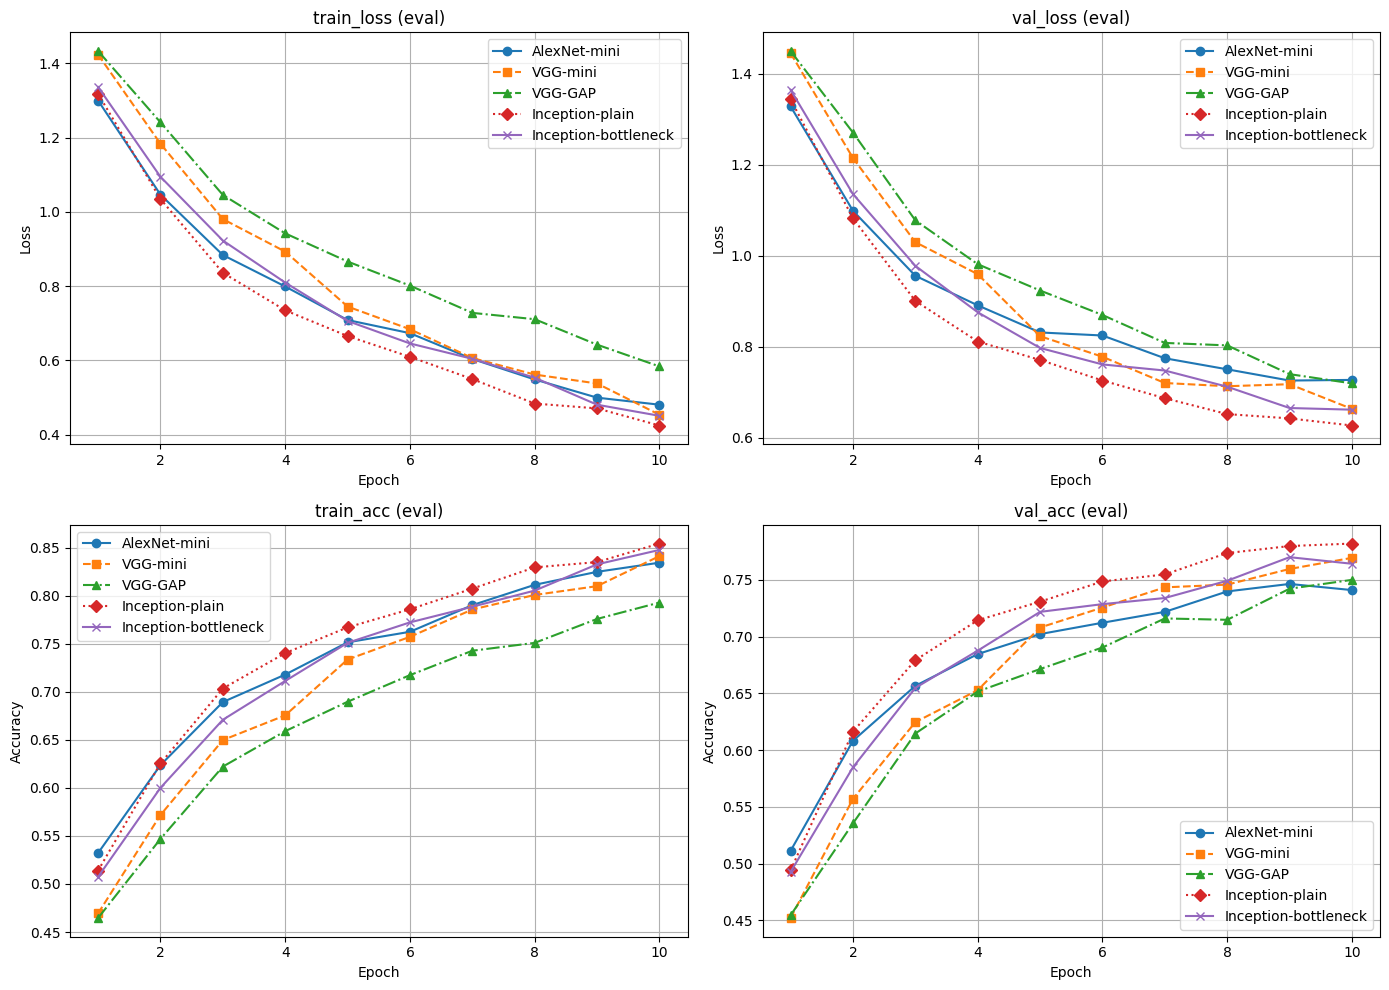

AlexNet-mini           | Params 194506 | Val loss 0.7253 at epoch  9 | Checkpoint acc 74.64% | Max acc 74.64% at epoch  9 | Train/eval 208.64s | Forward 3.121ms
VGG-mini               | Params 353962 | Val loss 0.6630 at epoch 10 | Checkpoint acc 76.94% | Max acc 76.94% at epoch 10 | Train/eval 216.36s | Forward 4.880ms
VGG-GAP                | Params 288298 | Val loss 0.7191 at epoch 10 | Checkpoint acc 75.00% | Max acc 75.00% at epoch 10 | Train/eval 217.46s | Forward 4.643ms
Inception-plain        | Params 268842 | Val loss 0.6265 at epoch 10 | Checkpoint acc 78.20% | Max acc 78.20% at epoch 10 | Train/eval 234.07s | Forward 4.860ms
Inception-bottleneck   | Params 211778 | Val loss 0.6613 at epoch 10 | Checkpoint acc 76.42% | Max acc 77.00% at epoch  9 | Train/eval 233.81s | Forward 5.710ms


In [9]:
plt.figure(figsize=(14, 10))
line_styles = ["-", "--", "-.", ":", "-"]
markers = ["o", "s", "^", "D", "x"]
for panel, metric in enumerate(["train_loss", "val_loss", "train_acc", "val_acc"]):
    plt.subplot(2, 2, panel+1)
    for i, name in enumerate(MODEL_NAMES):
        plt.plot(range(1, EPOCHS+1), results[name]["history"][metric],
                 linestyle=line_styles[i], marker=markers[i], label=name)
    plt.xlabel("Epoch")
    plt.ylabel("Loss" if "loss" in metric else "Accuracy")
    plt.title(metric + " (eval)")
    plt.grid(True)
    plt.legend()
plt.tight_layout()
plt.show()
plt.close()

for row in main_summary:
    print(f"{row['model']:22} | Params {row['parameters']:6} | Val loss {row['minimum_validation_loss']:.4f} at epoch {row['best_loss_epoch']:2} | Checkpoint acc {100*row['checkpoint_validation_accuracy']:.2f}% | Max acc {100*row['maximum_validation_accuracy']:.2f}% at epoch {row['maximum_accuracy_epoch']:2} | Train/eval {row['training_including_evaluation_seconds']:.2f}s | Forward {row['median_forward_ms']:.3f}ms")


VGG-mini {'checkpoint_epoch': 10, 'top_two_error_classes': [{'class': 'dog', 'errors': 226}, {'class': 'cat', 'errors': 216}], 'shown_examples': [{'true': 'cat', 'predicted': 'dog'}, {'true': 'bird', 'predicted': 'ship'}, {'true': 'dog', 'predicted': 'cat'}, {'true': 'dog', 'predicted': 'bird'}]}


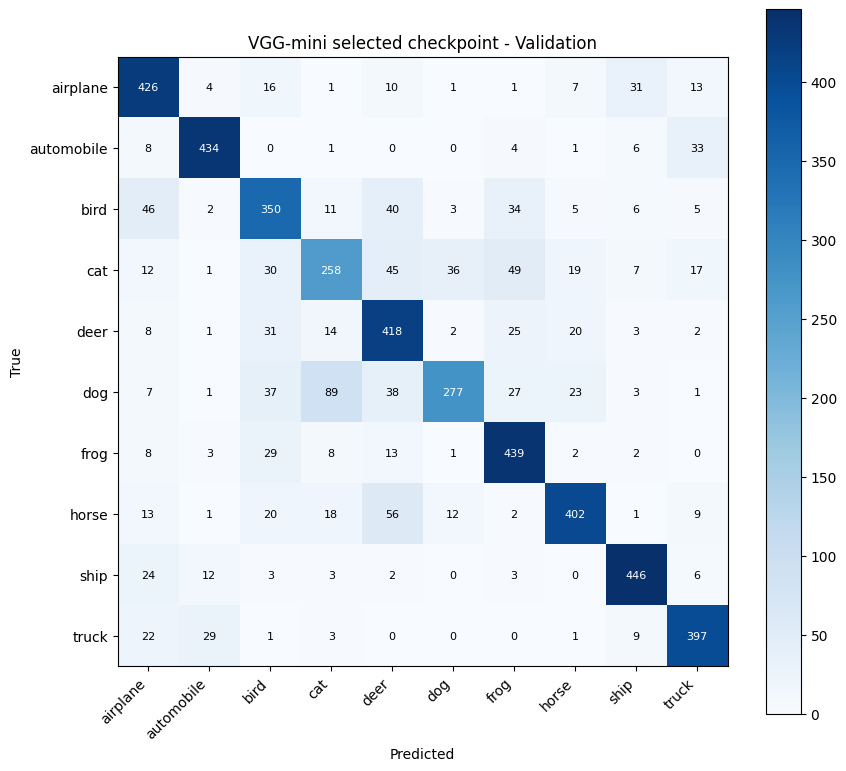

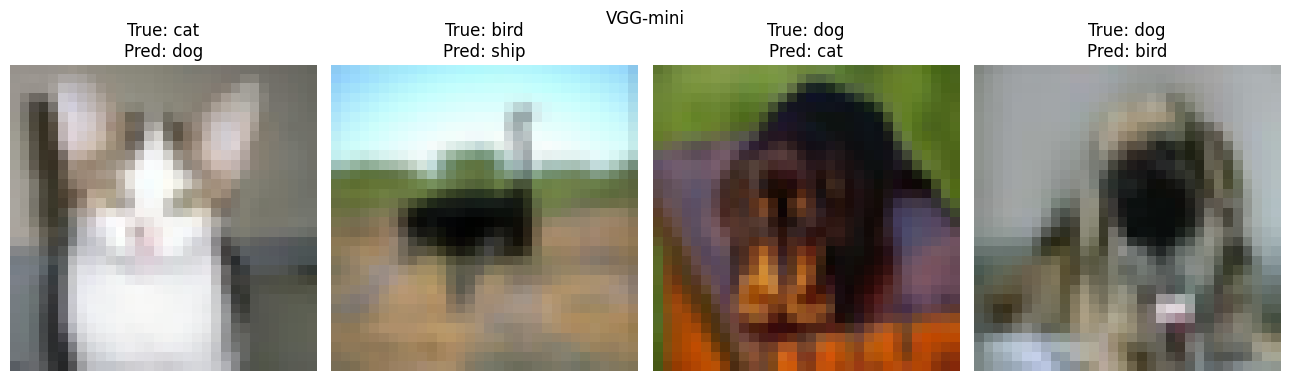

Inception-bottleneck {'checkpoint_epoch': 10, 'top_two_error_classes': [{'class': 'dog', 'errors': 241}, {'class': 'bird', 'errors': 166}], 'shown_examples': [{'true': 'dog', 'predicted': 'horse'}, {'true': 'bird', 'predicted': 'ship'}, {'true': 'dog', 'predicted': 'deer'}, {'true': 'ship', 'predicted': 'automobile'}]}


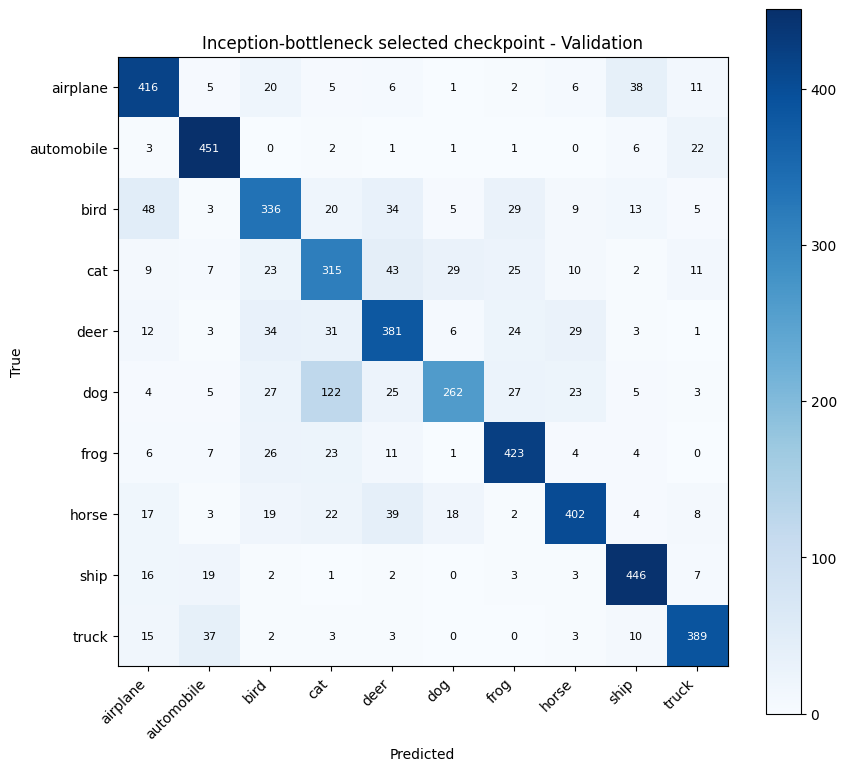

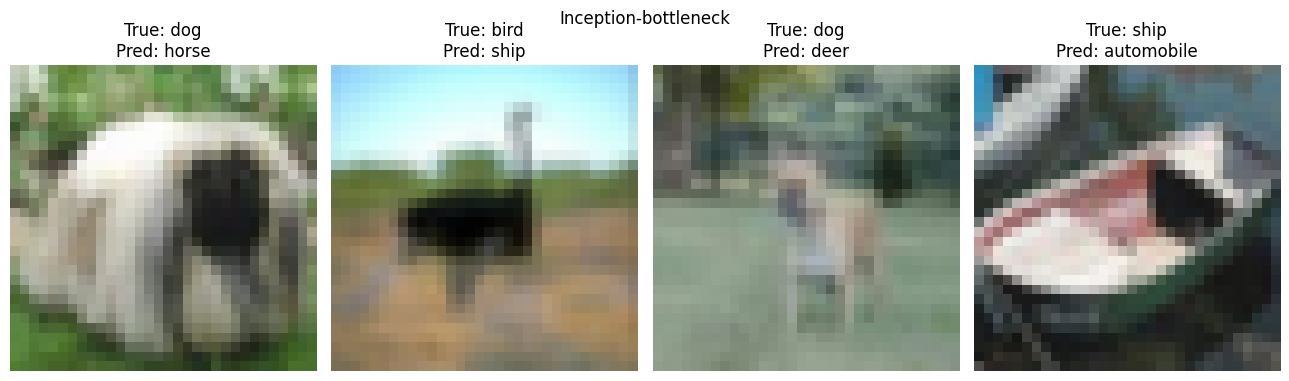

In [10]:
def predictions_and_errors(model):
    model.eval()
    labels, predictions, examples = [], [], []
    with torch.no_grad():
        for x, y in val_loader:
            pred = model(x.to(device)).argmax(1).cpu()
            labels.extend(y.tolist())
            predictions.extend(pred.tolist())
            for i in range(len(y)):
                if pred[i].item() != y[i].item() and len(examples) < 4:
                    examples.append((x[i], y[i].item(), pred[i].item()))
    return np.array(labels), np.array(predictions), examples

class_rows = []
class_accuracies = {}
error_summaries = {}
for name in ["VGG-mini", "Inception-bottleneck"]:
    model = results[name]["model"]
    labels, predictions, examples = predictions_and_errors(model)
    cm = confusion_matrix(labels, predictions, labels=list(range(10)))
    counts = cm.sum(axis=1)
    correct = cm.diagonal()
    errors = counts - correct
    class_acc = correct / counts
    class_accuracies[name] = class_acc
    for i in range(10):
        class_rows.append({"model": name, "class": classes[i], "count": int(counts[i]),
                           "correct": int(correct[i]), "errors": int(errors[i]), "accuracy": float(class_acc[i])})
    top = np.argsort(-errors)[:2]
    error_summaries[name] = {"checkpoint_epoch": results[name]["summary"]["best_loss_epoch"],
                             "top_two_error_classes": [{"class": classes[i], "errors": int(errors[i])} for i in top],
                             "shown_examples": [{"true": classes[y], "predicted": classes[p]} for image, y, p in examples]}
    print(name, error_summaries[name])

    plt.figure(figsize=(9, 8))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(10), classes, rotation=45, ha="right")
    plt.yticks(range(10), classes)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, str(cm[i,j]), ha="center", va="center",
                     color="white" if cm[i,j] > cm.max()/2 else "black", fontsize=8)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(name + " selected checkpoint - Validation")
    plt.tight_layout()
    plt.show()
    plt.close()

    if examples:
        plt.figure(figsize=(13, 4))
        for i, (image, label, prediction) in enumerate(examples):
            image = image.permute(1, 2, 0).numpy()
            image = np.clip(image * np.array(STD) + np.array(MEAN), 0, 1)
            plt.subplot(1, len(examples), i+1)
            plt.imshow(image)
            plt.title("True: " + classes[label] + "\nPred: " + classes[prediction])
            plt.axis("off")
        plt.suptitle(name)
        plt.tight_layout()
        plt.show()
        plt.close()


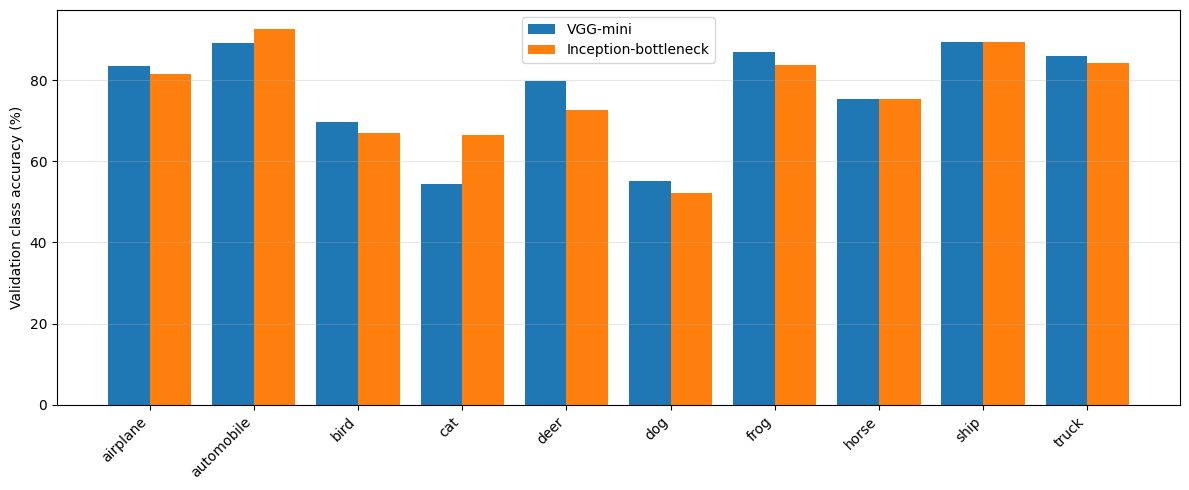

In [11]:
x = np.arange(10)
plt.figure(figsize=(12, 5))
plt.bar(x-0.2, 100*class_accuracies["VGG-mini"], width=0.4, label="VGG-mini")
plt.bar(x+0.2, 100*class_accuracies["Inception-bottleneck"], width=0.4, label="Inception-bottleneck")
plt.xticks(x, classes, rotation=45, ha="right")
plt.ylabel("Validation class accuracy (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()


In [12]:
seed_rows = []
for name in ["Inception-plain", "Inception-bottleneck"]:
    seed_rows.append(dict(results[name]["summary"]))
for seed in [123, 2026]:
    for name in ["Inception-plain", "Inception-bottleneck"]:
        extra_result = train_model(name, seed)
        seed_rows.append(dict(extra_result["summary"]))
        del extra_result

stability_rows = []
for name in ["Inception-plain", "Inception-bottleneck"]:
    rows = sorted([row for row in seed_rows if row["model"] == name], key=lambda r:r["seed"])
    accuracies = [row["checkpoint_validation_accuracy"] for row in rows]
    stability_rows.append({"model": name, "seed42_accuracy": accuracies[0],
                            "seed123_accuracy": accuracies[1], "seed2026_accuracy": accuracies[2],
                            "mean_accuracy": float(np.mean(accuracies)),
                            "standard_deviation_population": float(np.std(accuracies, ddof=0))})
for row in stability_rows:
    print(row)
rankings = []
for seed in [42, 123, 2026]:
    pair = {row["model"]: row["checkpoint_validation_accuracy"] for row in seed_rows if row["seed"] == seed}
    difference = pair["Inception-bottleneck"] - pair["Inception-plain"]
    rankings.append({"seed": seed, "bottleneck_minus_plain_percentage_points": 100*difference,
                     "winner": "tie" if difference == 0 else ("Inception-bottleneck" if difference > 0 else "Inception-plain")})
print(rankings)


Inception-plain Seed 123 Epoch 01/10 | Train Loss 1.2757 Acc 0.5315 | Val Loss 1.3105 Acc 0.5192
Inception-plain Seed 123 Epoch 02/10 | Train Loss 0.9731 Acc 0.6458 | Val Loss 1.0231 Acc 0.6364
Inception-plain Seed 123 Epoch 03/10 | Train Loss 0.8535 Acc 0.6948 | Val Loss 0.9210 Acc 0.6732
Inception-plain Seed 123 Epoch 04/10 | Train Loss 0.7060 Acc 0.7507 | Val Loss 0.7949 Acc 0.7162
Inception-plain Seed 123 Epoch 05/10 | Train Loss 0.6027 Acc 0.7906 | Val Loss 0.7156 Acc 0.7440
Inception-plain Seed 123 Epoch 06/10 | Train Loss 0.5800 Acc 0.7972 | Val Loss 0.7139 Acc 0.7552
Inception-plain Seed 123 Epoch 07/10 | Train Loss 0.4672 Acc 0.8392 | Val Loss 0.6443 Acc 0.7702
Inception-plain Seed 123 Epoch 08/10 | Train Loss 0.4320 Acc 0.8462 | Val Loss 0.6476 Acc 0.7766
Inception-plain Seed 123 Epoch 09/10 | Train Loss 0.4317 Acc 0.8499 | Val Loss 0.6343 Acc 0.7804
Inception-plain Seed 123 Epoch 10/10 | Train Loss 0.3650 Acc 0.8750 | Val Loss 0.6489 Acc 0.7796
{
  "model": "Inception-plain"

In [13]:
eligible = [row for row in main_summary if row["parameters"] <= 300000]
assert eligible
best_accuracy = max(row["checkpoint_validation_accuracy"] for row in eligible)
close_models = [row for row in eligible
                if best_accuracy - row["checkpoint_validation_accuracy"] <= 0.003 + 1e-12]
chosen = min(close_models, key=lambda row: (row["median_forward_ms"], row["parameters"]))
selected_name = chosen["model"]
selected_model = results[selected_name]["model"]
selection = {"eligible_models": [r["model"] for r in eligible],
             "best_eligible_validation_accuracy": best_accuracy,
             "within_0.3_percentage_points": [r["model"] for r in close_models],
             "selected_model": selected_name, "seed": SEED,
             "checkpoint_epoch": chosen["best_loss_epoch"],
             "checkpoint_validation_accuracy": chosen["checkpoint_validation_accuracy"],
             "checkpoint_validation_loss": chosen["minimum_validation_loss"],
             "parameters": chosen["parameters"], "median_forward_ms": chosen["median_forward_ms"],
             "selection_rule": "main seed42 checkpoints; <=300000 parameters; accuracy within 0.3 percentage points of best; prefer fastest forward"}
print(json.dumps(selection, indent=2))


{
  "eligible_models": [
    "AlexNet-mini",
    "VGG-GAP",
    "Inception-plain",
    "Inception-bottleneck"
  ],
  "best_eligible_validation_accuracy": 0.782,
  "within_0.3_percentage_points": [
    "Inception-plain"
  ],
  "selected_model": "Inception-plain",
  "seed": 42,
  "checkpoint_epoch": 10,
  "checkpoint_validation_accuracy": 0.782,
  "checkpoint_validation_loss": 0.6264826062202453,
  "parameters": 268842,
  "median_forward_ms": 4.8602475001189305,
  "selection_rule": "main seed42 checkpoints; <=300000 parameters; accuracy within 0.3 percentage points of best; prefer fastest forward"
}


In [14]:
# Final Test
if "final_test_result_ex2" not in globals():
    test_data = datasets.CIFAR10("data", train=False, download=True, transform=transform)
    test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
    test_loss, test_acc = evaluate(selected_model, test_loader)
    final_test_result_ex2 = {
        "model": selected_name, "seed": SEED,
        "checkpoint_epoch": chosen["best_loss_epoch"],
        "test_loss": test_loss, "test_accuracy": test_acc,
        "prior_notebook_test_viewed": True
    }
print(final_test_result_ex2)


{'model': 'Inception-plain', 'seed': 42, 'checkpoint_epoch': 10, 'test_loss': 0.6425753888130188, 'test_accuracy': 0.7791, 'prior_notebook_test_viewed': True}
